# W05. Fenotypowanie cyfrowe

**Wersja źródła:** 1.1.0 · **Data:** 2026-11-03

Dane syntetyczne EMA: 36 osób × 14 dni

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
print("NumPy:", np.__version__, "pandas:", pd.__version__)


NumPy: 2.5.4 pandas: 3.1.1


## Pozyskanie i zakres pomiarów
Aktywne: stres samoopisowy 0–10. Pasywne lub pochodne: kroki, czas użycia telefonu; sen jest w tej symulacji estymowany.

In [ ]:
sciezka = Path("pi_w05_data.csv")
if not sciezka.exists():
    raise FileNotFoundError("Prześlij pi_w05_data.csv do katalogu notebooka.")
dane = pd.read_csv(sciezka)
assert dane.shape == (504, 6)
assert dane.osoba.nunique() == 36
assert dane.sen_h.between(4, 10).all()
assert dane.stres.dropna().between(0, 10).all()
assert not dane.duplicated(["osoba", "dzien"]).any()
print(dane.head())
liczba_brakow = int(dane.stres.isna().sum())
assert liczba_brakow == 34
print("Brakujące EMA:", liczba_brakow)


   osoba  dzien  sen_h  kroki  telefon_min  stres
0      1      1   8.30   8515          312    5.4
1      1      2   8.00   7313          308    4.9
2      1      3   7.30   6211          288    5.6
3      1      4   6.96   5800          257    6.8
4      1      5   7.32   6300          223    6.8
Brakujące EMA: 34


## Kompletność pomiarów
Oblicz odsetek odpowiedzi EMA dla każdego uczestnika. Nie imputuj brakujących wyników zerami.

In [ ]:
kompletnosc = dane.groupby("osoba").stres.apply(lambda s: s.notna().mean())
print("Odpowiedzi EMA [%]:", round(100 * dane.stres.notna().mean(), 1))
print(kompletnosc.describe().round(3))
assert kompletnosc.between(0, 1).all()


Odpowiedzi EMA [%]: 93.3
count    36.000
mean      0.933
std       0.074
min       0.714
25%       0.929
50%       0.929
75%       1.000
max       1.000
Name: stres, dtype: float64


## Profile dzienne
Wyznacz średnie poziomy snu, kroków i czasu telefonu dla każdej osoby.

In [ ]:
profile = dane.groupby("osoba").agg(
    sen_h=("sen_h", "mean"),
    kroki=("kroki", "mean"),
    telefon_min=("telefon_min", "mean"),
    stres=("stres", "mean"),
)
print(profile.round(2).head())


       sen_h    kroki  telefon_min  stres
osoba                                    
1       7.54  7245.57       257.00   5.88
2       7.63  7641.79       232.21   6.08
3       7.63  7895.29       198.07   5.60
4       7.29  7962.79       169.14   4.87
5       6.93  7832.71       157.57   4.34


## Wizualizacja
Oddziel osie snu [h] i stresu [0–10]. Braki odpowiedzi pozostają widoczne jako przerwy.

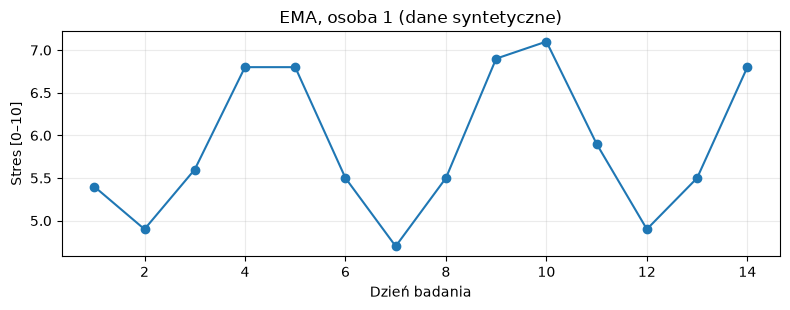

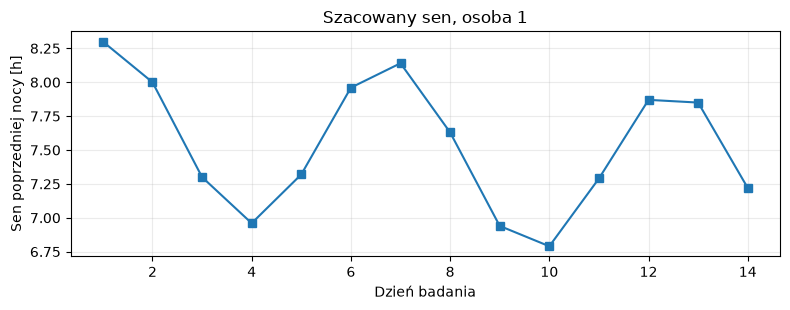

In [ ]:
osoba1 = dane.loc[dane.osoba == 1].sort_values("dzien")
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(osoba1.dzien, osoba1.stres, "o-")
ax.set(xlabel="Dzień badania", ylabel="Stres [0–10]",
       title="EMA, osoba 1 (dane syntetyczne)")
ax.grid(alpha=.25)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(osoba1.dzien, osoba1.sen_h, "s-")
ax.set(xlabel="Dzień badania", ylabel="Sen poprzedniej nocy [h]",
       title="Szacowany sen, osoba 1")
ax.grid(alpha=.25)
fig.tight_layout()
plt.show()


## Porównanie poziomów analizy
Wewnątrzosobnicza korelacja po centrowaniu opisuje zmiany dzienne względem średniej danej osoby. Międzyosobnicza korelacja dotyczy średnich osób.

In [ ]:
pary = dane.dropna(subset=["sen_h", "stres"]).copy()
for nazwa in ("sen_h", "stres"):
    pary[nazwa+"_c"] = (
        pary[nazwa] - pary.groupby("osoba")[nazwa].transform("mean")
    )
assert len(pary) == 470
r_wewn = pary["sen_h_c"].corr(pary["stres_c"])
r_miedzy = pary.groupby("osoba").sen_h.mean().corr(
    pary.groupby("osoba").stres.mean()
)
print(f"r_wewn = {r_wewn:.3f}; r_miedzy = {r_miedzy:.3f}")
assert -1 <= r_wewn <= 1 and -1 <= r_miedzy <= 1


r_wewn = -0.542; r_miedzy = -0.042


## Granice wnioskowania
Dane panelowe z 14 dni zawierają zależne pomiary 36 uczestników. W symulacji część braków samooceny stresu zależy od wartości przed jej usunięciem. W rzeczywistym badaniu mechanizm braków wymaga dodatkowych założeń i analizy wrażliwości.